# Class 5 Assignment: Feature Engineering, Feature Selection, and Randomized Search

## Part 1 — Load and Understand the Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv"

df = pd.read_csv(url)

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


In [2]:
# Shape
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns)

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Descriptive statistics
df.describe()

Shape: (398, 7)

Columns:
Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model-year'],
      dtype='object')

Data types:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model-year        int64
dtype: object

Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      2
weight          0
acceleration    0
model-year      0
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
count,398.000000,398.000000,398.000000,396.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.189394,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.402030,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,92.000000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


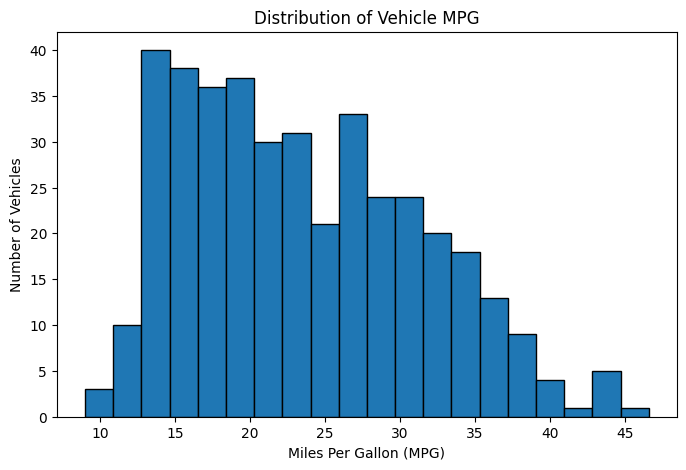

In [3]:
plt.figure(figsize=(8, 5))

plt.hist(df["mpg"], bins=20, edgecolor="black")

plt.title("Distribution of Vehicle MPG")
plt.xlabel("Miles Per Gallon (MPG)")
plt.ylabel("Number of Vehicles")

plt.show()

Part 1 Questions:

1. **What does one row represent?**
   - Each row represents one vehicle and its characteristics, including engine size, horsepower, weight, model year, and fuel efficiency.

2. **What is the prediction target?**
   - The prediction target is `mpg` (miles per gallon), which measures a vehicle's fuel efficiency.

3. **Why is this a regression problem?**
   - This is a regression problem because we are predicting a continuous numerical value (MPG) rather than a category or class.

4. **Which columns could potentially be useful predictors?**
   - The potential predictors are `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, and `model-year`. These characteristics may help predict a vehicle's fuel efficiency.

5. **Which columns contain missing values?**
   - Only the `horsepower` column contains missing values, with 2 missing entries out of 398 rows. All other columns have no missing values.

## Part 2 — Create the Final Train/Test Split


In [4]:
# Define the target (what we want to predict)
y = df["mpg"]

# Define the predictors (everything except mpg)
X = df.drop(columns=["mpg"])

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training predictors: (318, 6)
Testing predictors: (80, 6)
Training target: (318,)
Testing target: (80,)


### Part 2 Questions:

1. **Why do we create the test set before experimenting?**
   - We create the test set before experimenting so we have separate data to evaluate how well the final model performs on unseen data.

2. **Why shouldn't we repeatedly check test MAE while creating features?**
   - Repeatedly checking test MAE could influence our decisions when creating features, causing us to indirectly optimize the model for the test set instead of unseen data.

3. **What would happen if we kept modifying the model until the test score improved?**
   - The model could become overfitted to the test set, making the test score less reliable as a measure of how well the model will perform on new data.

## Part 3 — Establish a Baseline

In [6]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate the average MPG from training data
mean_mpg = y_train.mean()

# Predict the same average MPG for every training row
mean_predictions = np.full(len(y_train), mean_mpg)

# Calculate regression metrics
mean_mae = mean_absolute_error(y_train, mean_predictions)
mean_rmse = np.sqrt(mean_squared_error(y_train, mean_predictions))
mean_r2 = r2_score(y_train, mean_predictions)

print("Mean MPG:", mean_mpg)
print("Mean Baseline MAE:", mean_mae)
print("Mean Baseline RMSE:", mean_rmse)
print("Mean Baseline R²:", mean_r2)

Mean MPG: 23.60817610062893
Mean Baseline MAE: 6.684739527708555
Mean Baseline RMSE: 7.918094623048818
Mean Baseline R²: 0.0


In [7]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# Select only original numerical predictors
X_train_num = X_train.select_dtypes(include="number")

print("Numerical predictors:")
print(X_train_num.columns)

Numerical predictors:
Index(['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration',
       'model-year'],
      dtype='object')


In [8]:
# Create pipeline with missing-value handling and Random Forest
rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(random_state=42)
)

In [9]:
# Evaluate Random Forest with 5-fold cross-validation
rf_scores = cross_val_score(
    rf_model,
    X_train_num,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

# Convert negative scores to positive MAE values
rf_mae_scores = -rf_scores

print("Random Forest CV MAE scores:", rf_mae_scores)
print("Mean CV MAE:", rf_mae_scores.mean())
print("CV MAE Standard Deviation:", rf_mae_scores.std())

Random Forest CV MAE scores: [1.98573438 1.9596875  2.36965625 2.51287302 2.04473016]
Mean CV MAE: 2.174536259920635
CV MAE Standard Deviation: 0.22414251549058867


In [10]:
results = pd.DataFrame({
    "Model": ["Mean Predictor", "Untuned Random Forest"],
    "MAE": [mean_mae, rf_mae_scores.mean()]
})

results

,Model,MAE
0,Mean Predictor,6.684740
1,Untuned Random Forest,2.174536


In [11]:
from sklearn.dummy import DummyRegressor

mean_cv_scores = -cross_val_score(
    DummyRegressor(strategy="mean"),
    X_train_num,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

comparison = pd.DataFrame({
    "Model": ["Mean Predictor", "Untuned Random Forest"],
    "Mean CV MAE": [mean_cv_scores.mean(), rf_mae_scores.mean()],
    "CV Std": [mean_cv_scores.std(), rf_mae_scores.std()]
})

comparison

,Model,Mean CV MAE,CV Std
0,Mean Predictor,6.696644,0.410364
1,Untuned Random Forest,2.174536,0.224143


### Part 3 Questions:

1. **What does the mean predictor accomplish?**
   - The mean predictor provides a simple baseline by predicting the average training MPG (23.61) for every vehicle. It gives us a starting point to compare more advanced models against.

2. **How does the untuned Random Forest compare with the simple baseline?**
   - The untuned Random Forest performs much better, with a mean CV MAE of 2.17 compared to 6.70 for the mean predictor. This means the Random Forest makes significantly smaller prediction errors on average.

3. **Why do we need a model baseline before trying to improve the feature set?**
   - We need a baseline to measure whether changes to the features actually improve the model. Without it, we wouldn't know if feature engineering or other improvements are helping.

### Part 5: Engineered Features

1. **Feature Name: Power-to-Weight Ratio**
   - **Formula:** `power_to_weight = horsepower / weight`
   - **Reasoning:** This feature measures engine power relative to vehicle weight. It may help predict MPG because vehicles with similar horsepower but different weights can have different fuel efficiency.

2. **Feature Name: Displacement per Cylinder**
   - **Formula:** `displacement_per_cylinder = displacement / cylinders`
   - **Reasoning:** This feature measures the average engine displacement per cylinder. It may help predict MPG by providing additional information about engine size and configuration.

3. **Feature Name: Weight per Horsepower**
   - **Formula:** `weight_per_hp = weight / horsepower`
   - **Reasoning:** This feature measures how much vehicle weight corresponds to each unit of horsepower. It may help predict MPG by describing the relationship between vehicle weight and engine power.

## Part 6 — Evaluate Feature Engineering


In [13]:
# Model A: Original numerical features
X_original = X_train.select_dtypes(include="number").copy()

# Model B: Original + engineered features
X_engineered = X_original.copy()

X_engineered["power_to_weight"] = (
    X_original["horsepower"] / X_original["weight"]
)

X_engineered["displacement_per_cylinder"] = (
    X_original["displacement"] / X_original["cylinders"]
)

X_engineered["weight_per_hp"] = (
    X_original["weight"] / X_original["horsepower"]
)

# Check the number of features
print("Original features:", X_original.shape[1])
print("Original + engineered features:", X_engineered.shape[1])

import numpy as np

X_engineered = X_engineered.replace(
    [np.inf, -np.inf], np.nan
)

Original features: 6
Original + engineered features: 9


In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# Same model configuration for both feature sets
model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(random_state=42)
)

In [16]:
# Model A: Original features
scores_original = -cross_val_score(
    model,
    X_original,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

# Model B: Original + engineered features
scores_engineered = -cross_val_score(
    model,
    X_engineered,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("Original feature MAE:", scores_original)
print("Engineered feature MAE:", scores_engineered)

Original feature MAE: [1.98573438 1.9596875  2.36965625 2.51287302 2.04473016]
Engineered feature MAE: [1.96201562 2.032625   2.30832812 2.58496825 2.03620635]


In [17]:
results_part6 = pd.DataFrame({
    "Feature Set": [
        "Original",
        "Original + Engineered"
    ],
    "Mean CV MAE": [
        scores_original.mean(),
        scores_engineered.mean()
    ],
    "CV Std": [
        scores_original.std(),
        scores_engineered.std()
    ]
})

results_part6

,Feature Set,Mean CV MAE,CV Std
0,Original,2.174536,0.224143
1,Original + Engineered,2.184829,0.232493


### Part 6 Questions:

1. **Did feature engineering improve CV performance?**
   - No, feature engineering slightly worsened performance. The mean CV MAE increased from 2.1745 to 2.1848.

2. **Was the improvement large?**
   - There was no improvement. The MAE increased by only about 0.01, which is a very small difference.

3. **Did all engineered features necessarily help?**
   - No, adding the three engineered features did not improve overall performance. However, these results do not tell us whether individual engineered features were helpful.

4. **If performance became worse, does that mean the experiment failed?**
   - No, the experiment was still useful because it showed that adding these engineered features did not improve the model's cross-validation performance. This helps us make better decisions about which features to use.

## Part 7: Feature Importance

In [18]:
# Train the Random Forest using engineered features
rf_engineered = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(random_state=42)
)

rf_engineered.fit(X_engineered, y_train)

print("Random Forest trained successfully.")
print("Number of features:", X_engineered.shape[1])

Random Forest trained successfully.
Number of features: 9


In [19]:
# Access the trained Random Forest
trained_rf = rf_engineered.named_steps["randomforestregressor"]

# Display the feature names
print("Features used:")
print(X_engineered.columns.tolist())

# Confirm that the model has feature importance information
print("\nFeature importance available:",
      hasattr(trained_rf, "feature_importances_"))

Features used:
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year', 'power_to_weight', 'displacement_per_cylinder', 'weight_per_hp']

Feature importance available: True


## Part 8: Built-In Random Forest Feature Importance

In [20]:
# Access the trained Random Forest
trained_rf = rf_engineered.named_steps["randomforestregressor"]

# Get feature importance scores
importances = trained_rf.feature_importances_

# Create a DataFrame with feature names and importance scores
importance_df = pd.DataFrame({
    "Feature": X_engineered.columns,
    "Importance": importances
})

# Sort from highest to lowest importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df

,Feature,Importance
1,displacement,0.416871
2,horsepower,0.167919
3,weight,0.123549
0,cylinders,0.117829
5,model-year,0.102311
7,displacement_per_cylinder,0.028303
4,acceleration,0.020870
8,weight_per_hp,0.011425
6,power_to_weight,0.010925


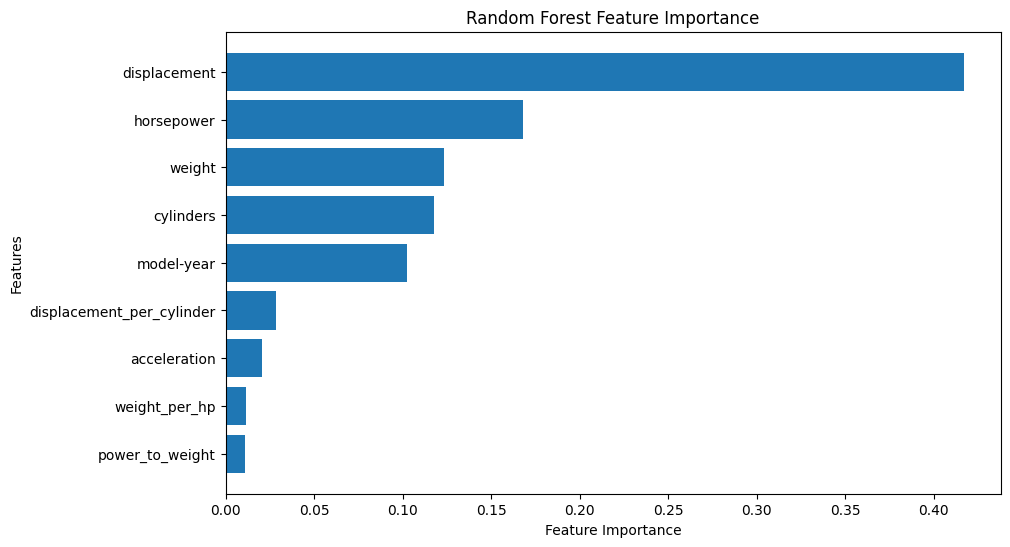

In [21]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()

### Part 8 Questions:

1. **Which features appear most important?**
   - Displacement is the most important feature (0.4169), followed by horsepower (0.1679), weight (0.1235), and cylinders (0.1178).

2. **Which appear least important?**
   - Power-to-weight ratio (0.0109) and weight per horsepower (0.0114) have the lowest importance scores, followed by acceleration (0.0209).

3. **Are any engineered features highly ranked?**
   - No, all three engineered features ranked relatively low. Displacement per cylinder was the highest-ranked engineered feature (0.0283), but it was still much lower than the original features.

4. **Did any result surprise you?**
   - I was surprised that displacement was much more important than the other features. I also expected the engineered features to rank higher, especially power-to-weight ratio, since both horsepower and weight are individually important.

## Part 9: Permutation Importance

In [22]:
from sklearn.model_selection import train_test_split

X_dev, X_val, y_dev, y_val = train_test_split(
    X_engineered,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Development set:", X_dev.shape)
print("Validation set:", X_val.shape)

Development set: (254, 9)
Validation set: (64, 9)


In [23]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

rf_perm = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(random_state=42)
)

rf_perm.fit(X_dev, y_dev)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=42))])

In [24]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_perm,
    X_val,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42
)

perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Permutation Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

perm_df = perm_df.sort_values(
    by="Permutation Importance",
    ascending=False
)

perm_df

,Feature,Permutation Importance,Std
5,model-year,1.573536,0.234336
3,weight,1.277620,0.100374
2,horsepower,1.143095,0.138047
1,displacement,0.884519,0.113449
0,cylinders,0.452795,0.102387
7,displacement_per_cylinder,0.128947,0.065204
8,weight_per_hp,0.036561,0.010588
6,power_to_weight,0.032773,0.020852
4,acceleration,0.020916,0.046365


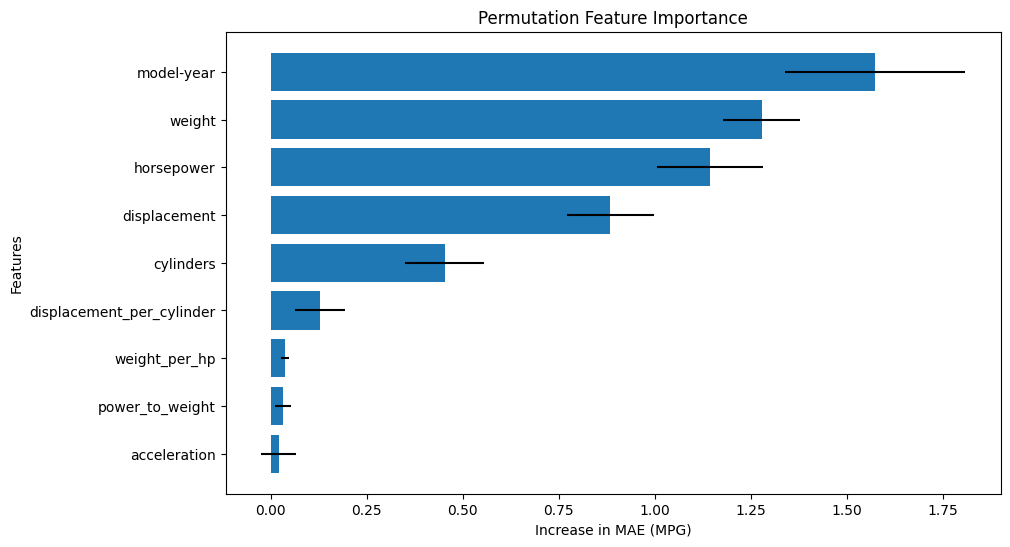

In [25]:
plt.figure(figsize=(10, 6))

plt.barh(
    perm_df["Feature"],
    perm_df["Permutation Importance"],
    xerr=perm_df["Std"]
)

plt.xlabel("Increase in MAE (MPG)")
plt.ylabel("Features")
plt.title("Permutation Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [26]:
# Built-in importance rankings
built_in = importance_df.copy()
built_in["Built-in Rank"] = (
    built_in["Importance"].rank(ascending=False, method="min")
)

# Permutation importance rankings
permutation = perm_df.copy()
permutation["Permutation Rank"] = (
    permutation["Permutation Importance"].rank(
        ascending=False,
        method="min"
    )
)

# Combine the rankings
ranking_comparison = pd.merge(
    built_in[["Feature", "Built-in Rank"]],
    permutation[["Feature", "Permutation Rank"]],
    on="Feature"
)

ranking_comparison = ranking_comparison.sort_values(
    by="Built-in Rank"
)

ranking_comparison

,Feature,Built-in Rank,Permutation Rank
0,displacement,1.0,4.0
1,horsepower,2.0,3.0
2,weight,3.0,2.0
3,cylinders,4.0,5.0
4,model-year,5.0,1.0
5,displacement_per_cylinder,6.0,6.0
6,acceleration,7.0,9.0
7,weight_per_hp,8.0,7.0
8,power_to_weight,9.0,8.0


### Part 9 Questions:

1. **Which features have the highest permutation importance?**
   - Model-year has the highest permutation importance (1.5735), followed by weight (1.2776), horsepower (1.1431), and displacement (0.8845).

2. **Which have low permutation importance?**
   - Acceleration (0.0209), power-to-weight ratio (0.0328), and weight per horsepower (0.0366) have the lowest permutation importance scores.

3. **Does the ranking agree with Random Forest's built-in importance?**
   - Not completely. Both methods rank the engineered features relatively low, but the top features differ. Built-in importance ranks displacement first, while permutation importance ranks model-year first.

4. **Why might the two importance methods disagree?**
   - The methods measure importance differently. Built-in importance measures how much each feature reduces prediction error within the trees, while permutation importance measures how much prediction performance worsens when a feature is shuffled. Correlated features can also cause differences because they may contain overlapping information.

### Part 10 Questions:

1. **Why can a feature receive low importance even though it contains useful information?**
   - A feature can receive low importance because it shares similar information with other features. For example, power-to-weight ratio uses horsepower and weight, which are already included in the model. The model may rely on those original features instead, giving the engineered feature a lower importance score.

2. **Why does feature importance not imply causation?**
   - Feature importance shows how much a model relies on a feature to make predictions, but it does not prove that the feature directly causes changes in MPG. A feature might be important because it is correlated with other factors that influence fuel efficiency.

## Part 11 — Feature Selection

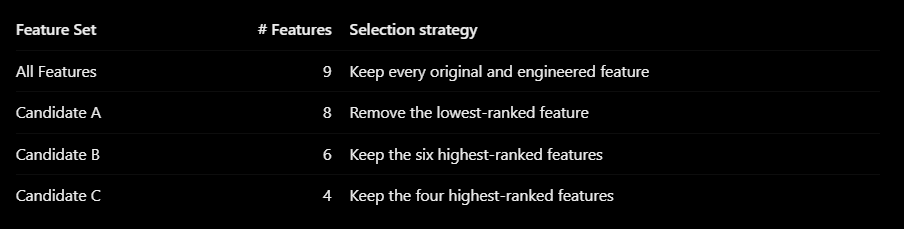

In [27]:
# Part 11: Define feature sets

feature_sets = {
    "All Features": X_engineered.columns.tolist(),

    "Candidate A": [
        col for col in X_engineered.columns
        if col != "acceleration"
    ],

    "Candidate B": [
        "model-year",
        "weight",
        "horsepower",
        "displacement",
        "cylinders",
        "displacement_per_cylinder"
    ],

    "Candidate C": [
        "model-year",
        "weight",
        "horsepower",
        "displacement"
    ]
}

# Display the selected features
for name, features in feature_sets.items():
    print(name, ":", len(features), "features")
    print(features)
    print()

All Features : 9 features
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year', 'power_to_weight', 'displacement_per_cylinder', 'weight_per_hp']

Candidate A : 8 features
['cylinders', 'displacement', 'horsepower', 'weight', 'model-year', 'power_to_weight', 'displacement_per_cylinder', 'weight_per_hp']

Candidate B : 6 features
['model-year', 'weight', 'horsepower', 'displacement', 'cylinders', 'displacement_per_cylinder']

Candidate C : 4 features
['model-year', 'weight', 'horsepower', 'displacement']



In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# Store the evaluation results
selection_results = []

# Evaluate each feature set
for name, features in feature_sets.items():

    # Select the columns for this feature set
    X_subset = X_engineered[features]

    # Create the same model for each experiment
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(random_state=42)
    )

    # Run 5-fold cross-validation
    scores = -cross_val_score(
        model,
        X_subset,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    # Save the results
    selection_results.append({
        "Feature Set": name,
        "Number of Features": len(features),
        "Mean CV MAE": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

In [29]:
# Create comparison table
feature_selection_df = pd.DataFrame(selection_results)

# Round values for readability
feature_selection_df = feature_selection_df.round(4)

# Display results
feature_selection_df

,Feature Set,Number of Features,Mean CV MAE,CV Standard Deviation
0,All Features,9,2.1848,0.2325
1,Candidate A,8,2.2119,0.2244
2,Candidate B,6,2.2062,0.2380
3,Candidate C,4,2.2133,0.2441


### Part 11 Questions:

1. **Which feature set performs best?**
   - All Features performs best, with the lowest mean CV MAE of 2.1848.

2. **Can you remove some features without noticeably hurting performance?**
   - Yes. Candidate B uses only 6 features and has a mean CV MAE of 2.2062, which is only slightly higher than All Features (2.1848).

3. **Does the smallest feature set perform best?**
   - No. Candidate C uses only 4 features and has the highest mean CV MAE of 2.2133.

4. **If two feature sets perform almost identically, which would you choose and why?**
   - I would choose the smaller feature set because it is simpler and uses fewer predictors while maintaining nearly the same prediction accuracy.

### Part 12 Questions:

1. **Why does feature engineering come before feature selection?**
   - Feature engineering comes first because we can use existing features to create new ones that might help the model make better predictions. If we remove features too early, we might lose information needed to create useful engineered features.

2. **Explain this using one of your own engineered features.**
   - For example, my `displacement_per_cylinder` feature is calculated by dividing displacement by cylinders. If I had removed cylinders because of its relatively low importance, I wouldn't have been able to create this new feature. This shows why it is important to explore engineered features before deciding which original features to remove.

In [30]:
# Replace the name with your actual Part 13 selection
selected_feature_set = "Candidate B"

selected_features = feature_sets[selected_feature_set]

### Part 13: Selected Feature Set

I selected **Candidate B (6 features)** for hyperparameter tuning. It has a mean CV MAE of 2.2062 compared to 2.1848 for All Features, which is only a small difference. Its CV standard deviation (0.2380) is also close to All Features (0.2325). Candidate B uses three fewer features while maintaining similar prediction performance, making it a simpler choice for the next stage.

### Part 14 Questions:

1. **What is a hyperparameter?**
   - A hyperparameter is a setting chosen before training a model that controls how the model learns. For example, `max_depth` controls how deep the trees in a Random Forest can grow.

2. **How is a hyperparameter different from a learned model parameter?**
   - Hyperparameters are set before training, while learned model parameters are determined from the training data. For example, `max_depth` is a hyperparameter, while the split thresholds learned by a decision tree are model parameters.

3. **What does RandomizedSearchCV do?**
   - RandomizedSearchCV tests randomly selected combinations of hyperparameters using cross-validation to find settings that perform well.

4. **Why might Randomized Search be preferable to manually trying combinations?**
   - Randomized Search is more efficient because it automatically tests multiple combinations and compares their performance, saving time and reducing manual work.

5. **How is it different from GridSearchCV?**
   - GridSearchCV tests every combination of specified hyperparameter values, while RandomizedSearchCV tests a limited number of randomly selected combinations. This can make RandomizedSearchCV faster when there are many possible combinations.

## Part 15 — Build a RandomizedSearchCV


In [31]:
# Part 15: Prepare selected training features

X_selected = X_engineered[selected_features].copy()

print("Selected features:", X_selected.columns.tolist())
print("Training shape:", X_selected.shape)

Selected features: ['model-year', 'weight', 'horsepower', 'displacement', 'cylinders', 'displacement_per_cylinder']
Training shape: (318, 6)


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Create the pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(random_state=42))
])

# Approved hyperparameter ranges
param_distributions = {
    "rf__n_estimators": [100, 200, 300],
    "rf__max_depth": [5, 10, 15, None],
    "rf__max_features": [0.5, 0.75, 1.0],
    "rf__min_samples_split": [2, 5, 10],
    "rf__min_samples_leaf": [1, 2, 4]
}

# Configure RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

In [33]:
# Train and tune using training data only
random_search.fit(X_selected, y_train)

print("RandomizedSearchCV completed successfully.")
print("Number of sampled combinations:", random_search.n_iter)

RandomizedSearchCV completed successfully.
Number of sampled combinations: 25


### Part 16: Explain the Hyperparameters

1. **n_estimators**
   - Controls the number of trees in the Random Forest. Increasing the number of trees can make predictions more stable, but it also increases training time.

2. **max_depth**
   - Controls how deep each tree can grow. Deeper trees can learn more complex patterns but may overfit the training data. Smaller depths limit model complexity.

3. **max_features**
   - Controls the proportion of features considered when finding the best split. Using fewer features adds randomness to the trees, while using more features allows each split to consider more information.

4. **min_samples_split**
   - Controls the minimum number of samples required to split a node. Higher values make trees less complex by preventing splits when there are too few samples.

5. **min_samples_leaf**
   - Controls the minimum number of samples that must remain in each leaf. Higher values prevent very small leaf groups and can help reduce overfitting.

## Part 17: Examine Randomized Search Results

In [34]:
# Part 17: Best RandomizedSearchCV results

print("Best Hyperparameters:")
print(random_search.best_params_)

print("\nBest Mean CV MAE:")
print(-random_search.best_score_)

Best Hyperparameters:
{'rf__n_estimators': 100, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 4, 'rf__max_features': 0.75, 'rf__max_depth': 10}

Best Mean CV MAE:
2.1733143302753453


In [35]:
# Convert randomized search results into a DataFrame
search_results = pd.DataFrame(random_search.cv_results_)

# Create a table with the useful columns
top_results = search_results[[
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "param_rf__n_estimators",
    "param_rf__max_depth",
    "param_rf__max_features",
    "param_rf__min_samples_split",
    "param_rf__min_samples_leaf"
]].copy()

# Convert negative MAE into positive MAE
top_results["mean_test_score"] = -top_results["mean_test_score"]

# Rename columns
top_results = top_results.rename(columns={
    "rank_test_score": "Rank",
    "mean_test_score": "CV MAE",
    "std_test_score": "CV Std",
    "param_rf__n_estimators": "n_estimators",
    "param_rf__max_depth": "max_depth",
    "param_rf__max_features": "max_features",
    "param_rf__min_samples_split": "min_samples_split",
    "param_rf__min_samples_leaf": "min_samples_leaf"
})

# Sort by rank and display the top 10 combinations
top_results = top_results.sort_values("Rank")

top_results.head(10)

,Rank,CV MAE,CV Std,n_estimators,max_depth,max_features,min_samples_split,min_samples_leaf
5,1,2.173314,0.218121,100,10,0.75,2,4
23,2,2.174330,0.199280,200,10,0.50,2,1
15,3,2.179878,0.245299,300,None,1.00,5,1
11,4,2.185155,0.190370,300,15,0.50,2,1
0,5,2.189291,0.216453,100,10,0.75,10,4
17,6,2.191698,0.229159,300,10,0.75,10,1
21,7,2.192445,0.205193,300,None,0.75,2,1
6,8,2.193071,0.237662,100,15,1.00,5,1
2,9,2.193976,0.239457,300,10,1.00,2,1
16,10,2.196465,0.221070,300,None,0.75,10,4


In [36]:
# Compare each combination with the best CV MAE
best_mae = top_results["CV MAE"].min()

top_results["MAE Difference"] = (
    top_results["CV MAE"] - best_mae
)

# Show combinations within 0.05 MPG of the best
near_ties = top_results[
    top_results["MAE Difference"] <= 0.05
]

print("Combinations within 0.05 MPG of the best:")
display(near_ties)

Combinations within 0.05 MPG of the best:


,Rank,CV MAE,CV Std,n_estimators,max_depth,max_features,min_samples_split,min_samples_leaf,MAE Difference
5,1,2.173314,0.218121,100,10,0.75,2,4,0.000000
23,2,2.174330,0.199280,200,10,0.50,2,1,0.001016
15,3,2.179878,0.245299,300,None,1.00,5,1,0.006563
11,4,2.185155,0.190370,300,15,0.50,2,1,0.011841
0,5,2.189291,0.216453,100,10,0.75,10,4,0.015977
17,6,2.191698,0.229159,300,10,0.75,10,1,0.018383
21,7,2.192445,0.205193,300,None,0.75,2,1,0.019131
6,8,2.193071,0.237662,100,15,1.00,5,1,0.019757
2,9,2.193976,0.239457,300,10,1.00,2,1,0.020662
16,10,2.196465,0.221070,300,None,0.75,10,4,0.023151


### Part 17 Questions:

1. **Which combination performed best?**
   - The best combination used 100 trees, max_depth of 10, max_features of 0.75, min_samples_split of 2, and min_samples_leaf of 4. It achieved the lowest mean CV MAE of 2.1733.

2. **Were several combinations very similar?**
   - Yes, several combinations had very similar results. The second-best combination had a CV MAE of 2.1743, only about 0.001 higher than the best. This suggests that multiple hyperparameter combinations performed almost equally well.

3. **Did any best value occur at the edge of your search range?**
   - Yes. The best combination used n_estimators = 100, min_samples_split = 2, and min_samples_leaf = 4, which were boundary values of their search ranges.

4. **If so, what might that suggest?**
   - Boundary values might suggest that testing values outside those ranges could be useful. For example, we could investigate fewer than 100 trees or more than 4 samples per leaf. However, this does not guarantee better performance, so another search is not automatically necessary.

5. **What would you investigate next?**
   - I would investigate whether the small differences between the top combinations are meaningful by comparing their CV variability. I would also consider testing nearby hyperparameter values using training data only, without using the final test set.

## Part 18: Compare the Modeling Stages

In [37]:
# Part 18: Retrieve CV MAE results

# Part 3: Baseline Random Forest
baseline_mae = rf_mae_scores.mean()

# Part 6: Original + engineered features
engineered_mae = scores_engineered.mean()

# Part 11: Selected feature set
selected_mae = feature_selection_df.loc[
    feature_selection_df["Feature Set"] == selected_feature_set,
    "Mean CV MAE"
].iloc[0]

# Part 15: Tuned Random Forest
tuned_mae = -random_search.best_score_

In [38]:
# Create the Part 18 summary table

part18_results = pd.DataFrame({
    "Stage": [
        "Baseline RF",
        "Feature Engineering",
        "Feature Selection",
        "Randomized Search"
    ],

    "Feature Set / Model": [
        "Original Features",
        "Original + Engineered",
        selected_feature_set,
        "Selected + Tuned RF"
    ],

    "CV MAE": [
        baseline_mae,
        engineered_mae,
        selected_mae,
        tuned_mae
    ]
})

# Display the results
part18_results.round(4)

,Stage,Feature Set / Model,CV MAE
0,Baseline RF,Original Features,2.1745
1,Feature Engineering,Original + Engineered,2.1848
2,Feature Selection,Candidate B,2.2062
3,Randomized Search,Selected + Tuned RF,2.1733


In [39]:
# Calculate the change in CV MAE between stages
part18_results["MAE Change"] = (
    part18_results["CV MAE"].diff()
)

part18_results.round(4)

,Stage,Feature Set / Model,CV MAE,MAE Change
0,Baseline RF,Original Features,2.1745,NaN
1,Feature Engineering,Original + Engineered,2.1848,0.0103
2,Feature Selection,Candidate B,2.2062,0.0214
3,Randomized Search,Selected + Tuned RF,2.1733,-0.0329


### Part 18 Questions:

1. **Which stage produced the largest improvement?**
   - Randomized Search produced the largest improvement, reducing CV MAE from 2.2062 to 2.1733, an improvement of approximately 0.0329.

2. **Did feature engineering help?**
   - No, feature engineering slightly worsened performance. CV MAE increased from 2.1745 to 2.1848.

3. **Did feature selection help?**
   - No, feature selection slightly worsened performance. Candidate B had a CV MAE of 2.2062 compared to 2.1848 with all nine features.

4. **Did hyperparameter tuning help?**
   - Yes, hyperparameter tuning improved performance. The tuned model achieved a CV MAE of 2.1733, slightly better than the original baseline of 2.1745.

5. **Was every additional step beneficial?**
   - No, not every step improved performance. Feature engineering and feature selection slightly increased prediction error, while hyperparameter tuning reduced it. This shows that adding complexity does not always lead to better results.

## Part 19: Final Test Evaluation

In [40]:
[
    "model-year",
    "weight",
    "horsepower",
    "displacement",
    "cylinders",
    "displacement_per_cylinder"
]

['model-year',
 'weight',
 'horsepower',
 'displacement',
 'cylinders',
 'displacement_per_cylinder']

In [41]:
# Part 19: Prepare test data using Candidate B

selected_features = feature_sets["Candidate B"]

X_test_selected = X_test[selected_features[:5]].copy()

# Calculate the engineered feature
X_test_selected["displacement_per_cylinder"] = (
    X_test["displacement"] / X_test["cylinders"]
)

# Ensure identical feature order
X_test_selected = X_test_selected[selected_features]

print("Test data shape:", X_test_selected.shape)
print("Features:", X_test_selected.columns.tolist())

Test data shape: (80, 6)
Features: ['model-year', 'weight', 'horsepower', 'displacement', 'cylinders', 'displacement_per_cylinder']


In [42]:
# Retrieve the best fitted model
final_model = random_search.best_estimator_

# Predict MPG on the held-out test set
y_pred = final_model.predict(X_test_selected)

print("Final predictions created:", len(y_pred))

Final predictions created: 80


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate final Random Forest predictions
final_mae = mean_absolute_error(y_test, y_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
final_r2 = r2_score(y_test, y_pred)

print("Final Random Forest Results:")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R²:", final_r2)

Final Random Forest Results:
MAE: 1.7408724956905843
RMSE: 2.3061061368278013
R²: 0.9010883900180799


In [44]:
# Mean baseline predictions
baseline_predictions = np.full(
    len(y_test),
    y_train.mean()
)

# Baseline evaluation
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

# Create comparison table
final_comparison = pd.DataFrame({
    "Model": [
        "Training Mean Baseline",
        "Tuned Random Forest"
    ],
    "MAE": [
        baseline_mae,
        final_mae
    ],
    "RMSE": [
        baseline_rmse,
        final_rmse
    ],
    "R²": [
        baseline_r2,
        final_r2
    ]
})

final_comparison.round(4)

,Model,MAE,RMSE,R²
0,Training Mean Baseline,5.9554,7.3473,-0.0040
1,Tuned Random Forest,1.7409,2.3061,0.9011


### Part 19 Questions:

1. **How does final test performance compare with CV performance?**
   - The final test MAE was 1.7409, which is lower than the CV MAE of 2.1733. This means the model performed better on the test set than it did during cross-validation.

2. **Is the result reasonably consistent with what cross-validation suggested?**
   - Yes, the results are reasonably consistent. Both cross-validation and the final test evaluation show relatively low prediction errors, although the test MAE was slightly better.

3. **Did the final model substantially outperform the mean baseline?**
   - Yes, the tuned Random Forest performed much better. Its test MAE was 1.7409 compared to 5.9554 for the mean baseline. It also achieved an R² of 0.9011 compared to -0.0040 for the baseline.

4. **Is there evidence that your development process overfit the training data?**
   - There is no clear evidence of overfitting from these results. The final test MAE was lower than the CV MAE, suggesting that the model performed well on unseen data rather than only on the training data.

## Part 20: Actual vs. Predicted MPG

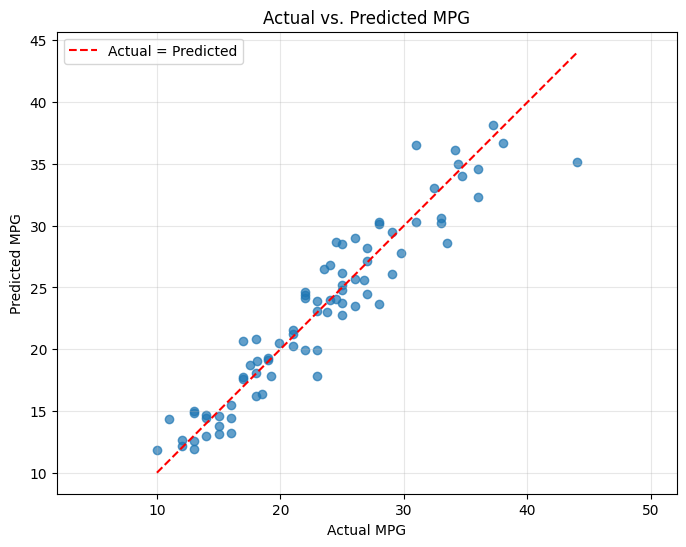

In [45]:
# Part 20: Actual vs. Predicted MPG

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Plot actual vs. predicted MPG
plt.scatter(y_test, y_pred, alpha=0.7)

# Add the perfect prediction line
min_mpg = min(y_test.min(), y_pred.min())
max_mpg = max(y_test.max(), y_pred.max())

plt.plot(
    [min_mpg, max_mpg],
    [min_mpg, max_mpg],
    color="red",
    linestyle="--",
    label="Actual = Predicted"
)

# Labels and title
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs. Predicted MPG")

plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")

plt.show()

### Part 20 Questions:

1. **Are predictions generally close to the diagonal?**
   - Yes, most predictions are close to the diagonal line, indicating that the model generally predicts MPG accurately.

2. **Where does the model make larger errors?**
   - The larger errors appear at higher MPG values, especially around 30–45 MPG. For example, one vehicle with an actual MPG of approximately 44 was predicted at around 35 MPG.

3. **Does the model appear better at predicting some MPG ranges than others?**
   - Yes, the model appears more accurate for vehicles in the middle MPG range, approximately 15–30 MPG, where most points are clustered near the diagonal. Predictions at higher MPG values show more noticeable errors.

## Part 21: Residual Analysis

In [46]:
# Part 21: Calculate residuals

residuals = y_test.to_numpy() - y_pred

print("First 10 residuals:")
print(residuals[:10])

First 10 residuals:
[ 2.41099719 -2.32055866 -0.2503276  -2.00055197 -0.44563846  2.49159618
 -2.83131285  1.09810598 -0.78837538  0.76000875]


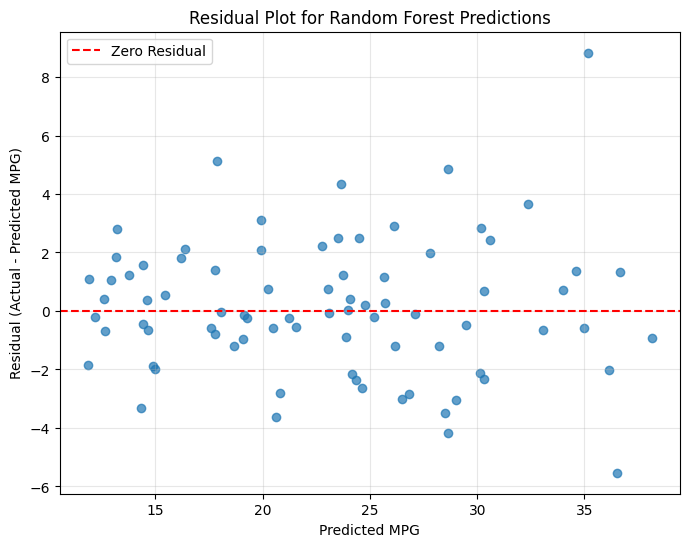

In [47]:
# Part 21: Residual plot

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.7)

# Zero-reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.xlabel("Predicted MPG")
plt.ylabel("Residual (Actual - Predicted MPG)")
plt.title("Residual Plot for Random Forest Predictions")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

### Part 21 Questions:

1. **Do residuals appear randomly distributed around zero?**
   - Yes, most residuals appear scattered around the zero line, with both positive and negative values. This suggests that the model generally makes predictions without a strong consistent bias.

2. **Is there an obvious pattern?**
   - There is no clear pattern, but the residuals appear more spread out at higher predicted MPG values, suggesting larger prediction errors in that range.

3. **Does the model systematically overpredict or underpredict in any region?**
   - There is no strong evidence of systematic overprediction or underprediction. However, some higher predicted MPG values have large positive residuals, indicating that the model underpredicted those vehicles' actual MPG.

## Part 22: Inspect the Largest Prediction Errors

In [48]:
# Part 22: Create a DataFrame with prediction errors

error_df = X_test.copy()

# Add actual and predicted MPG
error_df["Actual MPG"] = y_test
error_df["Predicted MPG"] = y_pred

# Add residuals and absolute errors
error_df["Residual"] = residuals
error_df["Absolute Error"] = abs(residuals)

error_df.head()

,cylinders,displacement,horsepower,weight,acceleration,model-year,Actual MPG,Predicted MPG,Residual,Absolute Error
198,4,91.0,53.0,1795,17.4,76,33.0,30.589003,2.410997,2.410997
396,4,120.0,79.0,2625,18.6,82,28.0,30.320559,-2.320559,2.320559
33,6,232.0,100.0,2634,13.0,71,19.0,19.250328,-0.250328,0.250328
208,8,318.0,150.0,3940,13.2,76,13.0,15.000552,-2.000552,2.000552
93,8,318.0,150.0,4237,14.5,73,14.0,14.445638,-0.445638,0.445638


In [49]:
# Find the 10 vehicles with the largest absolute errors

largest_errors = error_df.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

largest_errors

,cylinders,displacement,horsepower,weight,acceleration,model-year,Actual MPG,Predicted MPG,Residual,Absolute Error
394,4,97.0,52.0,2130,24.6,82,44.0,35.168574,8.831426,8.831426
377,4,91.0,68.0,1970,17.6,82,31.0,36.531099,-5.531099,5.531099
298,8,350.0,125.0,3900,17.4,79,23.0,17.864807,5.135193,5.135193
238,4,98.0,83.0,2075,15.9,77,33.5,28.627811,4.872189,4.872189
30,4,140.0,90.0,2264,15.5,71,28.0,23.666822,4.333178,4.333178
196,4,98.0,60.0,2164,22.1,76,24.5,28.658794,-4.158794,4.158794
380,4,120.0,88.0,2160,14.5,82,36.0,32.356010,3.643990,3.643990
275,6,163.0,125.0,3140,13.6,78,17.0,20.635030,-3.635030,3.635030
172,4,90.0,71.0,2223,16.5,75,25.0,28.482482,-3.482482,3.482482
124,8,350.0,180.0,3664,11.0,73,11.0,14.309898,-3.309898,3.309898


In [52]:
# Select columns for the final Part 22 table

columns_to_show = [
    "Actual MPG",
    "Predicted MPG",
    "Residual",
    "Absolute Error",
    "model-year",
    "weight",
    "horsepower",
    "displacement",
    "cylinders"
]

largest_errors["displacement_per_cylinder"] = (
    largest_errors["displacement"] / largest_errors["cylinders"]
)

# Create and display the final table
largest_errors_table = largest_errors[columns_to_show]

largest_errors_table.round(2)

,Actual MPG,Predicted MPG,Residual,Absolute Error,model-year,weight,horsepower,displacement,cylinders
394,44.0,35.17,8.83,8.83,82,2130,52.0,97.0,4
377,31.0,36.53,-5.53,5.53,82,1970,68.0,91.0,4
298,23.0,17.86,5.14,5.14,79,3900,125.0,350.0,8
238,33.5,28.63,4.87,4.87,77,2075,83.0,98.0,4
30,28.0,23.67,4.33,4.33,71,2264,90.0,140.0,4
196,24.5,28.66,-4.16,4.16,76,2164,60.0,98.0,4
380,36.0,32.36,3.64,3.64,82,2160,88.0,120.0,4
275,17.0,20.64,-3.64,3.64,78,3140,125.0,163.0,6
172,25.0,28.48,-3.48,3.48,75,2223,71.0,90.0,4
124,11.0,14.31,-3.31,3.31,73,3664,180.0,350.0,8


### Part 22: Inspect the Largest Errors

1. **Vehicle 394**

   - **Observation:** This vehicle has an actual MPG of 44.0, but the model predicted 35.17 MPG. The residual is +8.83, meaning the model underestimated its fuel efficiency. This is the largest prediction error among the test vehicles.

   - **Hypothesis:** The vehicle may have fuel-saving characteristics that are not fully represented by the model's features. This could explain why its actual MPG is higher than predicted.

2. **Vehicle 377**

   - **Observation:** This vehicle has an actual MPG of 31.0, but the model predicted 36.53 MPG. The residual is -5.53, meaning the model overestimated its fuel efficiency. This is the second-largest absolute error.

   - **Hypothesis:** The model may have expected better fuel efficiency because the vehicle is relatively lightweight and has a small engine. However, other factors not included in the model may help explain its lower actual MPG.

## Part 23: Design One Additional Experiment

Experiment: Investigate whether removing weight_per_hp improves Random Forest performance.

Hypothesis: I expect removing weight_per_hp to have little effect on model performance because it contains overlapping information with power_to_weight.

In [53]:
# Part 23: Prepare feature sets

# Model A: All nine features
X_full = X_engineered.copy()

# Model B: Remove weight_per_hp
X_reduced = X_engineered.drop(
    columns=["weight_per_hp"]
)

print("Full feature set:", X_full.shape)
print("Reduced feature set:", X_reduced.shape)

Full feature set: (318, 9)
Reduced feature set: (318, 8)


In [54]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# Same untuned Random Forest for both models
experiment_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(random_state=42)
)

# Model A: All nine features
full_scores = -cross_val_score(
    experiment_model,
    X_full,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

# Model B: Eight features
reduced_scores = -cross_val_score(
    experiment_model,
    X_reduced,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

In [55]:
# Part 23: Compare experiment results

part23_results = pd.DataFrame({
    "Feature Set": [
        "All Features",
        "Without weight_per_hp"
    ],
    "Number of Features": [
        X_full.shape[1],
        X_reduced.shape[1]
    ],
    "Mean CV MAE": [
        full_scores.mean(),
        reduced_scores.mean()
    ],
    "CV Standard Deviation": [
        full_scores.std(),
        reduced_scores.std()
    ]
})

part23_results.round(4)

,Feature Set,Number of Features,Mean CV MAE,CV Standard Deviation
0,All Features,9,2.1848,0.2325
1,Without weight_per_hp,8,2.1689,0.2377


### Results:

All Features (9): Mean CV MAE = 2.1848, CV Std = 0.2325

Without weight_per_hp (8): Mean CV MAE = 2.1689, CV Std = 0.2377

### Conclusion:

Removing weight_per_hp slightly improved performance, reducing mean CV MAE by 0.0159.

However, the improvement was small, and CV variability increased slightly.

These results are consistent with the idea that weight_per_hp may be redundant because it contains information already represented by power_to_weight.

The experiment suggests that removing this feature may be reasonable, but the small improvement does not prove that the feature is useless.

## Part 24: AI Reflection

1. **What did you ask the AI?**
   - I asked AI to help me choose an additional experiment related to feature engineering and feature selection.

2. **What did it recommend?**
   - AI recommended testing whether removing `weight_per_hp` would improve Random Forest performance because it contains overlapping information with `power_to_weight`.

3. **Did you accept the recommendation?**
   - I accepted the recommendation and compared the original nine-feature model against an eight-feature model without `weight_per_hp`.

4. **Why or why not?**
   - The experiment made sense because `weight_per_hp` and `power_to_weight` represent the same relationship in opposite ways. I wanted to see whether removing one would affect prediction accuracy.

5. **How did you test the recommendation?**
   - I compared both feature sets using the same untuned Random Forest and 5-fold cross-validation on the training data. I compared their mean CV MAE and standard deviation without using the final test set.

6. **What evidence supported your final decision?**
   - The original nine-feature model had a mean CV MAE of 2.1848, while the eight-feature model achieved 2.1689. Removing `weight_per_hp` slightly improved prediction accuracy, although the standard deviation increased from 0.2325 to 0.2377. The improvement was small, but it suggested that the removed feature was not necessary for this particular model comparison.

### AI Suggestion Rejected or Modified

- I modified the earlier suggestion to use all three engineered features together by investigating whether `weight_per_hp` was redundant. Rather than assuming that more features would improve performance, I tested removing it using cross-validation. The experiment showed a small improvement in mean CV MAE, demonstrating why AI recommendations should be evaluated using actual results.

## Part 25: Final Reflection on the Workflow

**Complete Workflow:**

1. **Baseline:** I started by building a mean predictor and a basic Random Forest to see how well the model performed before making changes.
2. **Feature Engineering:** I created three new features using the existing vehicle information to see if they could help predict MPG.
3. **Cross-Validation:** I compared the original features with the engineered features to see whether adding them improved the model.
4. **Feature Importance:** I used built-in and permutation importance to understand which features the model relied on most.
5. **Feature Selection Experiment:** I tested different groups of features to see if removing some would affect prediction accuracy.
6. **Select Feature Set:** I chose Candidate B because it used fewer features while still performing similarly to the full feature set.
7. **RandomizedSearchCV:** I tested different combinations of hyperparameters to find settings that improved the Random Forest.
8. **Select Model:** I used the best model found through RandomizedSearchCV.
9. **Final Test Evaluation:** I tested the final model on data it had not seen before. It achieved an MAE of 1.7409 and an R² of 0.9011.

**1. Why is the order important?**
   - The order matters because each step helps us make better decisions in the next step. We first need a baseline to know where we started. Then we can test new features, figure out which ones are useful, and adjust the model's settings. Following this order helps us understand what actually improves performance instead of making random changes.

**2. At which steps should the final test set remain untouched?**
   - The final test set should not be used while creating features, comparing models, checking feature importance, selecting features, or tuning hyperparameters. It should only be used once the final model is ready so we can get a fair idea of how well it performs on new data.